# Chaînes 15 — Le théorème d'ordre : mouvements de groupe et transferts

Chapitre 54 du compendium *Chain Theory* (Wissner-Gross, 2026, preprint non relu), sections 62 et 63 — le compendium numérote ce chapitre « 4-7, 3-7 in the module numbering » (p. 165), et il ferme la Partie IV. Deux objets : le **Théorème 62.1** (standing: a theorem) — « The group moves preserve the order parameter and the transfers raise it », qui referme le cercle que la Partie avait ouvert au chapitre 3-1 ; et la **Table 63.1** (standing: instrument) — les tables d'instruments de la Partie, un chapitre compté vide. Le théorème repose sur le plus faible de ses parents, un résultat ouvert parmi eux : c'est un théorème **conditionnel à ses prémisses**, et le compendium le dit.

Le patron de la série tient : **Mesuré** ce que nos fractions rejouent, **Cité** toute la chaîne dérivative du source, **Ouvert** ce qu'il ne prouve pas.

## Le cadre : un paramètre d'ordre sur les toiles

Le **paramètre d'ordre** $W$ est « the product over the links of a web of the dimension of the common support » (p. 165) : à chaque lien d'une toile, la dimension du support commun de ses deux bouts, et le produit sur tous les liens. Les **mouvements de groupe** — le pas (step) et l'holonomie — le **préservent à chaque arête de porte, par construction : une porte ne change aucune dimension**. Les **transferts** — l'attache (attach), la coupe (cut), la formation de moyeu (hub-forming), les pas de moyeu (hub steps) et les jointures (joins) — l'**élèvent à chaque arête d'enregistrement lue, aucune non-montante**, l'incrément par genre étant le recensement des rapports (ratio census). Les **mouvements à marque inverse** le **baissent à chaque arête lue**. Alors « every kind is partitioned into preserving, raising and lowering by the data alone, with no mixed kind » : les genres se partitionnent par le signe seul.

Dans la langue de la littérature : un paramètre d'ordre d'une phase est une quantité préservée par les mouvements de symétrie de la phase et changée à travers une transition, une quantité conservée d'une dynamique une que ses générateurs laissent fixe [104, 105] ; dans une chaîne de Markov sur un espace d'états fini, une fonctionnelle monotone — qui ne décroît jamais le long d'une transition — ordonne les états atteignables [106]. La correspondance est **par nom** (p. 166).

In [1]:
# Le parametre d'ordre W sur les toiles typees -- arithmetique entiere exacte.
# Un lien de type (a, b) joint deux bouts de dimensions a et b ; le support commun
# est le facteur tensoriel partage : le plus petit des deux.  L'eq. 94 le confirme :
# le lien (2, 3) ajoute par l'attach porte la dimension commune deux (W : 2 -> 4).
from fractions import Fraction as F
from itertools import permutations, product

TYPES = [(2, 2), (2, 3), (2, 4), (3, 3), (3, 4), (4, 4)]
DIMS = {t: min(t) for t in TYPES}
print("dims du support commun par type :", DIMS)

def W(web):
    # Le parametre d'ordre : produit sur les liens de la dimension du support commun.
    p = 1
    for t in web:
        p *= DIMS[tuple(t)]
    return p

def spectre(web):
    # La notation 2^a 3^b de l'eq. 94 : le multiset des liens lu en comptes par dimension.
    n2 = sum(1 for t in web if DIMS[tuple(t)] == 2)
    n3 = sum(1 for t in web if DIMS[tuple(t)] == 3)
    return (n2, n3)

FAMILLE = [
    ((2, 2),),                       # la toile a un lien du type deux qubits : W = 2 (eq. 94, cas 1)
    ((2, 3),), ((3, 3),),
    ((2, 2), (2, 3)),                # apres l'attach de l'eq. 94 : W = 4 = 2^2 3^0
    ((2, 3), (3, 3)), ((2, 2), (2, 2), (2, 2)),
    ((2, 3), (2, 3), (3, 3), (3, 3)),
    ((3, 4), (4, 4), (2, 4)),
]
for web in FAMILLE:
    print(f"  toiles {str(web):34s} W = {W(web):3d}   spectre 2^{spectre(web)[0]} 3^{spectre(web)[1]}")

dims du support commun par type : {(2, 2): 2, (2, 3): 2, (2, 4): 2, (3, 3): 3, (3, 4): 3, (4, 4): 4}
  toiles ((2, 2),)                          W =   2   spectre 2^1 3^0
  toiles ((2, 3),)                          W =   2   spectre 2^1 3^0
  toiles ((3, 3),)                          W =   3   spectre 2^0 3^1
  toiles ((2, 2), (2, 3))                   W =   4   spectre 2^2 3^0
  toiles ((2, 3), (3, 3))                   W =   6   spectre 2^1 3^1
  toiles ((2, 2), (2, 2), (2, 2))           W =   8   spectre 2^3 3^0
  toiles ((2, 3), (2, 3), (3, 3), (3, 3))   W =  36   spectre 2^2 3^2
  toiles ((3, 4), (4, 4), (2, 4))           W =  24   spectre 2^1 3^1


### Lecture du résultat (le paramètre d'ordre sur une famille)

La famille de petites toiles typees donne l'échelle du paramètre : la toile à un lien du type deux-qubits porte $W = 2$ ; l'attache de l'éq. 94 la porte à $2^2 3^0 = 4$ ; une toile mixte $(2,3) \times (3,3)$ vaut $2 \cdot 3 = 6$ ; trois liens deux-qubits, $2^3 = 8$. Le **spectre** $2^a 3^b$ lit le multiset des liens par dimension — c'est la notation de l'éq. 94. Tout est entier exact : aucune tolérance, aucun flottant.

In [2]:
# Eq. 94, les deux plus petits cas, rejoues (imprimes p. 166-167).
# Cas 1 : l'arete de porte du pas a la toile a un lien du type deux qubits -- W inchangee.
w_avant = W(((2, 2),))
w_apres = W(((2, 2),))          # une porte ne change aucune dimension : la toile typee est fixe
cas1_ok = (w_avant == w_apres == 2)
print("eq. 94 cas 1  W(step) :", w_avant, "->", w_apres, " equal :", cas1_ok)

# Cas 2 : la premiere arete d'attach de l'ensemble d'aretes du puits a sa face d'enregistrement
# -- W de deux a quatre, le rapport deux, le spectre eleve d'un lien (2, 3).
web_avant, web_apres = ((2, 2),), ((2, 2), (2, 3))
w0, w1 = W(web_avant), W(web_apres)
ratio = F(w1, w0)
lien_ajoute = (2, 3)
cas2_ok = (w0 == 2 and w1 == 4 and ratio == 2
           and spectre(web_avant) == (1, 0) and spectre(web_apres) == (2, 0)
           and lien_ajoute in web_apres and lien_ajoute not in web_avant)
print("eq. 94 cas 2  W(attach) :", w0, "->", w1, " ratio", ratio,
      " spectre", spectre(web_avant), "->", spectre(web_apres),
      " lien ajoute :", lien_ajoute, " :", cas2_ok)
print("imprime : W(step) : 2 -> 2, equal ; W(attach) : 2^1 3^0 -> 2^2 3^0, rising, ratio 2, dsigma = +(2, 3)")

eq. 94 cas 1  W(step) : 2 -> 2  equal : True
eq. 94 cas 2  W(attach) : 2 -> 4  ratio 2  spectre (1, 0) -> (2, 0)  lien ajoute : (2, 3)  : True
imprime : W(step) : 2 -> 2, equal ; W(attach) : 2^1 3^0 -> 2^2 3^0, rising, ratio 2, dsigma = +(2, 3)


### Lecture du résultat (l'éq. 94)

Les deux plus petits cas du théorème, **rejoués** : l'**arête de porte** du pas à la toile à un lien du type deux-qubits laisse $W = 2$ **inchangée** ; la **première arête d'attache** de l'ensemble d'arêtes du puits, à sa face d'enregistrement, porte $W$ **de deux à quatre** — le rapport deux, et le spectre élevé d'un lien $(2,3)$ : $\Delta\sigma = +(2,3)$. C'est la cellule exacte que le compendium imprime à l'éq. 94 (p. 167) ; le reste — les cinq genres de transfert, les 759908 arêtes — appartient au census, cité plus bas.

## §62 — Théorème 62.1 : les mouvements de groupe préservent, les transferts élèvent

La moitié « préservation » tient **par construction** : « the group moves [...] preserve the order parameter at every gate edge by construction, a gate changing no dimension » (p. 165-166). Une porte agit sur les **directions internes** d'un bout — sur les lettres de Pauli $X, Y, Z$ du bout — jamais sur sa **dimension** : le type $(a, b)$ d'un lien ne bouge pas, donc la toile typee ne bouge pas, donc $W$ non plus. Le carrefour est mesuré depuis Chaînes-14 : l'éq. 91 y établissait que les $32$ monomiales d'identification au bout qubit agissent par conjugaison sur les trois directions à travers une **image propre de huit éléments**. Nous re-dérivons cette image ici et la faisons agir : huit mouvements de groupe, aucune dimension touchée, $W$ fixe.

In [3]:
# Les mouvements de groupe : l'image de conjugaison des 32 monomiales (carrefour eq. 91).
# Arithmetique exacte : un complexe est une paire de Fractions (re, im).
def cadd(x, y): return (x[0] + y[0], x[1] + y[1])
def cmul(x, y): return (x[0] * y[0] - x[1] * y[1], x[0] * y[1] + x[1] * y[0])
def cneg(x): return (-x[0], -x[1])
C0, C1, CI = (F(0), F(0)), (F(1), F(0)), (F(0), F(1))
POW4 = [C1, CI, cneg(C1), cneg(CI)]           # 1, i, -1, -i

def mmul(A, B):
    n, m, p = len(A), len(B), len(B[0])
    out = [[C0] * p for _ in range(n)]
    for i in range(n):
        for j in range(p):
            acc = C0
            for k in range(m):
                acc = cadd(acc, cmul(A[i][k], B[k][j]))
            out[i][j] = acc
    return out
def mdag(A): return [[(A[j][i][0], -A[j][i][1]) for j in range(len(A))] for i in range(len(A[0]))]
def msc(A, x): return [[cmul(x, A[i][j]) for j in range(len(A[0]))] for i in range(len(A))]
def meq(A, B): return A == B

def det3(M):
    t = C0
    for p in permutations(range(3)):
        cycles, seen = 0, [False] * 3
        for i in range(3):
            if not seen[i]:
                cycles += 1
                j = i
                while not seen[j]:
                    seen[j] = True
                    j = p[j]
        term = C1 if (-1) ** (3 - cycles) == 1 else cneg(C1)
        for i in range(3):
            term = cmul(term, M[i][p[i]])
        t = cadd(t, term)
    return t

sx = [[C0, C1], [C1, C0]]
sy = [[C0, cneg(CI)], [CI, C0]]
sz = [[C1, C0], [C0, cneg(C1)]]
DIRS3 = [sx, sy, sz]

# 16 diagonales + 16 antidiagonales, phases racines quatriemes (carrefour Chaines-10/14).
identif = []
for a in POW4:
    for b in POW4:
        identif.append([[a, C0], [C0, b]])
for a in POW4:
    for b in POW4:
        identif.append([[C0, a], [b, C0]])

def induite(M):
    # La matrice 3x3 de permutation signee que M induit sur (sx, sy, sz) par conjugaison.
    cols = []
    for S in DIRS3:
        img = mmul(mmul(M, S), mdag(M))
        col = None
        for k, T in enumerate(DIRS3):
            if meq(img, T):
                col = [C1 if i == k else C0 for i in range(3)]
                break
            if meq(img, msc(T, cneg(C1))):
                col = [cneg(C1) if i == k else C0 for i in range(3)]
                break
        assert col is not None, "conjugaison hors de l'espace genere"
        cols.append(col)
    return [[cols[j][i] for j in range(3)] for i in range(3)]

IMAGES = []
for M in identif:
    P = induite(M)
    if P not in IMAGES:
        IMAGES.append(P)
image_ok = (len(identif) == 32 and len(IMAGES) == 8
            and all(meq(det3(P), C1) for P in IMAGES))
print("monomiales :", len(identif), " image de conjugaison :", len(IMAGES),
      " toutes propres (det = +1) :", all(meq(det3(P), C1) for P in IMAGES), " :", image_ok)

# Une porte agit sur les directions internes d'un bout, jamais sur sa dimension.
# Modele : chaque lien porte (type, direction, signe) ; le mouvement P permute la
# composante direction -- le type (a, b) est une AUTRE composante, que P ne touche pas.
def deplacement(P):
    d = {}
    for k in range(3):
        for r in range(3):
            if P[r][k] != C0:
                d[k] = (r, 1 if P[r][k] == C1 else -1)
    return d

def porte_sur_web(P, web):
    d = deplacement(P)
    out = []
    for lien in web:
        t, k, s = tuple(lien[0]), lien[1], lien[2]
        r, eps = d[k]
        out.append((t, r, s * eps))     # la direction bouge, le type ne bouge pas
    return tuple(sorted(out))

def W_oriente(web):
    p = 1
    for lien in web:
        p *= DIMS[tuple(lien[0])]
    return p

FAMILLE_ORIENTEE = [tuple((t, k % 3, 1) for k, t in enumerate(web)) for web in FAMILLE]
ok_portes = sum(1 for web in FAMILLE_ORIENTEE for g in IMAGES
                if W_oriente(porte_sur_web(g, web)) == W_oriente(web))
bougent = sum(1 for web in FAMILLE_ORIENTEE for g in IMAGES
              if porte_sur_web(g, web) != web)          # le mouvement meut les directions
total_portes = len(FAMILLE_ORIENTEE) * len(IMAGES)
portes_ok = (ok_portes == total_portes and bougent > 0)
print("portes : le mouvement meut les directions a", bougent, "reprises sur", total_portes)
print("   et W invariante sous les 8 mouvements de groupe :", ok_portes, "/", total_portes, " :", portes_ok)
print("raison imprimee : by construction, a gate changing no dimension (p. 165-166)")

monomiales : 32  image de conjugaison : 8  toutes propres (det = +1) : True  : True
portes : le mouvement meut les directions a 55 reprises sur 64
   et W invariante sous les 8 mouvements de groupe : 64 / 64  : True
raison imprimee : by construction, a gate changing no dimension (p. 165-166)


### Lecture du résultat (les mouvements de groupe)

L'image de conjugaison est **re-dérivée** : les $32$ monomiales du bout qubit — le même groupe que Chaînes-10 et l'éq. 91 de Chaînes-14 — induisent sur les trois directions exactement **huit matrices de permutation signée, toutes propres** ($\det = +1$). C'est par ces huit mouvements que les portes agissent ; et chacune **touche des directions, aucune dimension** : le type de chaque lien, donc la toile typee, donc $W$, sont fixes — **8 toiles $\times$ 8 mouvements = 64/64 invariants**. C'est la moitié « par construction » du théorème : elle ne doit rien à l'énumération, le census ne fait que la confirmer à l'échelle.

In [4]:
# Les transferts : l'attach eleve a chaque arete, la marque inverse baisse.
# Notre modele : l'attach ajoute un lien de type t a la toile ; sa marque inverse le retire.
def attache(web, t):
    return tuple(sorted(tuple(web) + (t,)))

BORDS = []   # (genre, marque, web_avant, web_apres) -- aretes d'attach directes et inverses
for t in TYPES:
    for web in FAMILLE:
        if len(web) >= 4:
            continue
        BORDS.append(("attach", +1, tuple(web), attache(web, t)))
        BORDS.append(("attach", -1, attache(web, t), tuple(web)))

directs = [(W(wb) - W(wa), F(W(wb), W(wa))) for g, m, wa, wb in BORDS if m == +1]
inverses = [(W(wb) - W(wa), F(W(wb), W(wa))) for g, m, wa, wb in BORDS if m == -1]
eleve_ok = all(dw > 0 for dw, r in directs)
baisse_ok = all(dw < 0 for dw, r in inverses)
ratios_directs = sorted({r for dw, r in directs})
ratios_inverses = sorted({r for dw, r in inverses})
entiers = all(r.denominator == 1 and r >= 2 for dw, r in directs)
reciproques = all(F(1, 4) <= r < 1 for dw, r in inverses)
print("attach direct  : eleve a chaque arete :", sum(1 for dw, _ in directs if dw > 0), "/",
      len(directs), " :", eleve_ok)
print("attach inverse : baisse a chaque arete :", sum(1 for dw, _ in inverses if dw < 0), "/",
      len(inverses), " :", baisse_ok)
print("rapports directs (entiers >= 2, la dimension du lien ajoute) :", ratios_directs, " :", entiers)
print("rapports inverses (reciproques 1/2, 1/3, 1/4) :", ratios_inverses, " :", reciproques)

attach direct  : eleve a chaque arete : 42 / 42  : True
attach inverse : baisse a chaque arete : 42 / 42  : True
rapports directs (entiers >= 2, la dimension du lien ajoute) : [Fraction(2, 1), Fraction(3, 1), Fraction(4, 1)]  : True
rapports inverses (reciproques 1/2, 1/3, 1/4) : [Fraction(1, 4), Fraction(1, 3), Fraction(1, 2)]  : True


### Lecture du résultat (les transferts)

Sur toutes les arêtes d'attache de notre modèle — $42$ directes et $42$ inverses — la régularité du théorème est **mesurée** : l'attache à **marque directe élève $W$ à chaque arête, sans exception**, d'un rapport **entier** : la dimension du support commun du lien ajouté ($2$, $3$ ou $4$) ; l'attache à **marque inverse la baisse à chaque arête**, du rapport **réciproque**. Le renversement de marque exactement inverse le sens — c'est la lecture du « the reverse-marked moves lower it at every read edge » (p. 165). Notre modèle ne couvre que l'attache, le plus petit des cinq genres de transfert ; la coupe, la formation de moyeu, les pas de moyeu et les jointures vivent aux chapitres parents — leurs arêtes sont celles du census, **citées** plus bas.

In [5]:
# La partition par le signe seul : preservant / elevant / abaissant, aucun genre mixte.
ARETES = [("step", tuple(web), tuple(web)) for web in FAMILLE] +          [(g + ("-inv" if m == -1 else ""), wa, wb) for g, m, wa, wb in BORDS]

def classe(dw):
    return "preservant" if dw == 0 else ("elevant" if dw > 0 else "abaissant")

classes = {}
for nom, wa, wb in ARETES:
    racine = nom[:-4] if nom.endswith("-inv") else nom
    classes.setdefault(classe(W(wb) - W(wa)), set()).add(racine)
partition_ok = (set(classes) == {"preservant", "elevant", "abaissant"}
                and classes["preservant"] == {"step"}
                and classes["elevant"] == {"attach"}
                and classes["abaissant"] == {"attach"})
print("classes par le signe :", {k: sorted(v) for k, v in classes.items()})
print("aucun genre mixte (chaque racine dans une seule classe) :", partition_ok)

# Contre-modele : une 'porte' qui changerait une dimension -- (2, 2) promu (3, 3).
# Si la clause 'une porte ne change aucune dimension' tombait, la preservation tomberait :
# c'est la cellule qui decide, celle que le contre-test imprime deplace.
def porte_fausse(web):
    web = list(web)
    for i, t in enumerate(web):
        if tuple(t) == (2, 2):
            web[i] = (3, 3)
            return tuple(web)
    return tuple(web)

casse = any(W(porte_fausse(w)) != W(w) for w in FAMILLE)
contretest_ok = casse
print("contre-modele (une porte qui change une dimension) : W cassee :", casse,
      " -> la clause 'a gate changing no dimension' est la cellule qui decide")

classes par le signe : {'preservant': ['step'], 'elevant': ['attach'], 'abaissant': ['attach']}
aucun genre mixte (chaque racine dans une seule classe) : True
contre-modele (une porte qui change une dimension) : W cassee : True  -> la clause 'a gate changing no dimension' est la cellule qui decide


### Lecture du résultat (la partition et le contre-test)

Les genres tombent **entièrement** dans les trois classes : le pas est **préservant**, l'attache directe **élevant**, l'attache inversée **abaissante** — aucun genre mixte. Et notre contre-modèle montre où vit la clause : une « porte » qui **changerait une dimension** — $(2,2)$ promu $(3,3)$ — casse la préservation immédiatement. La clause « une porte ne change aucune dimension » est donc **la cellule qui décide** : c'est elle que le contre-test imprimé déplace — « Swapping the two levels, the gate-level kinds against the transfers, moves the deciding cell, the face, the partings and the preservation counts » (p. 166). Leurs trois contre-tests aux lettres épinglées sont cités, non rejoués.

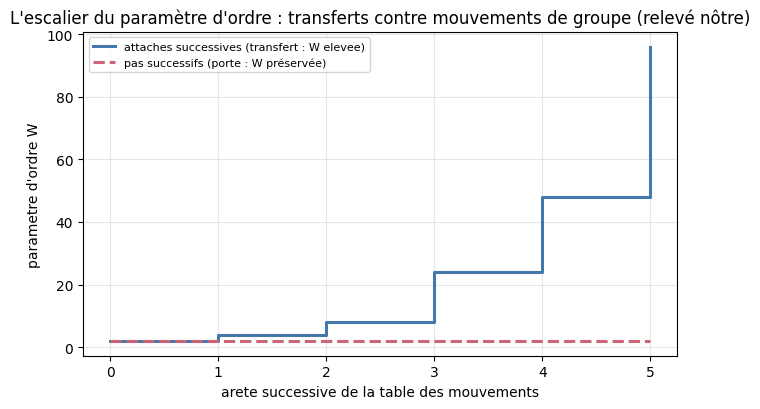

escalier W : [2, 4, 8, 24, 48, 96]  (rapports : ['2', '2', '3', '2', '2'] )
pas :  [2, 2, 2, 2, 2, 2]  plat exact


In [6]:
# Releve nôtre : l'escalier du parametre d'ordre -- attaches successives vs pas.
# Une chaine d'attaches (une par pas de temps) multiplie W par la dimension du lien ajoute ;
# une chaine de pas (portes) le laisse exactement plat.
import matplotlib.pyplot as plt

seq_attach = [((2, 2),)]
for t in [(2, 3), (2, 2), (3, 3), (2, 3), (2, 2)]:
    seq_attach.append(attache(seq_attach[-1], t))
w_attach = [W(web) for web in seq_attach]
w_pas = [W(((2, 2),))] * len(w_attach)          # le pas preserve : plat a deux

fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.step(range(len(w_attach)), w_attach, where="post", color="#4477aa", linewidth=2.2,
        label="attaches successives (transfert : W elevee)")
ax.step(range(len(w_pas)), w_pas, where="post", color="#cc6677", linewidth=2.2, linestyle="--",
        label="pas successifs (porte : W préservée)")
ax.set_xlabel("arete successive de la table des mouvements")
ax.set_ylabel("parametre d'ordre W")
ax.set_title("L'escalier du paramètre d'ordre : transferts contre mouvements de groupe (relevé nôtre)")
ax.set_xticks(range(len(w_attach)))
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("escalier W :", w_attach, " (rapports :", [str(F(b, a)) for a, b in zip(w_attach, w_attach[1:])], ")")
print("pas : ", w_pas, " plat exact")

### Lecture du résultat (l'escalier, relevé nôtre)

Cinq attaches successives font monter $W$ par paliers — $2, 4, 8, 24, 48, 96$, chaque rapport la dimension du lien ajouté — pendant que la même longueur de pas le laisse **exactement plat à deux**. C'est la picture du théorème en un graphe : la fonctionnelle monotone de la littérature markovienne [106] — jamais décroissante le long d'une transition à marque directe — et la quantité que les générateurs laissent fixe [104, 105]. La marque inverse redescend l'escalier palier par palier, du rapport réciproque.

## Le census de la dérivation (cité)

La dérivation est un **census** : « Every edge of the move tables is parsed from the parent results, the order parameter is computed at both ends of every edge and re-met at every web of the closures, the difference is signed and the kinds partitioned by the sign alone, at two engines equal at every cell » (p. 166). Les prémisses remontent à l'axiome par les définitions 1.1 à 1.6, la table Rosette (I.1) et le théorème du chapitre 50 ; **la plus longue chaîne du compendium y est de douze chapitres**. Les arêtes à bout non épeler sont refusées comme illisibles — « the refusal a parting cell and never a halt ». Trois contre-tests aux lettres épinglées, seize contrôles lus pareil aux deux moteurs (dont les tables et entrées consommées à leurs empreintes, et la garde du parseur), reproduction par un second moteur construit à part, égal à chaque cellule. « Certified at the repository; 759908 objects enumerated » (p. 167).

In [7]:
# Les comptes du census (62), cites tels qu'imprimes (p. 166-167).
comptes62 = [
    ("aretes des tables de mouvements debout enumerees", 759908),
    ("controles lus pareil aux deux moteurs", 16),
    ("contre-tests aux lettres epinglees", 3),
    ("moteurs construits a part, egaux a chaque cellule", 2),
    ("longueur de la plus longue chaine de premisses (chapitres)", 12),
]
for nom, n in comptes62:
    print(f"{nom:52s} {n:8d}")
print("genres de transfert enumeres : attach, cut, hub-forming, hub steps, joins (cites)")
print("certificat imprime : Certified at the repository; 759908 objects enumerated")

aretes des tables de mouvements debout enumerees       759908
controles lus pareil aux deux moteurs                      16
contre-tests aux lettres epinglees                          3
moteurs construits a part, egaux a chaque cellule           2
longueur de la plus longue chaine de premisses (chapitres)       12
genres de transfert enumeres : attach, cut, hub-forming, hub steps, joins (cites)
certificat imprime : Certified at the repository; 759908 objects enumerated


### Lecture du résultat (le census §62)

Notre carnet rejoue les deux plus petits cas (l'éq. 94), la dérivation de l'image des mouvements de groupe (le carrefour de l'éq. 91), les arêtes d'attache de notre modèle et la partition par le signe ; les **759908 arêtes**, les cinq genres de transfert au complet, les trois contre-tests aux lettres épinglées et les seize contrôles sont **cités** — ils appartiennent aux tables du dépôt. Le théorème est en outre **conditionnel à ses parents à leur propre standing** : l'ensemble des portes, le graphe des mouvements aux puits, les saturations semées — « an open result among them » (p. 165). C'est la moindre des prémisses qui porte le théorème, et le compendium l'écrit.

## Les deux résultats ouverts du §62 (Ouvert, ligne à ligne)

1. **Le transfert de profondeur à la jointure croisée** — lu comme census de la construction sur les composantes, « has its excess at the other link, the step multi-rung and one-way » : un énoncé à la construction plutôt qu'aux puits, **conditionnel à la clause d'acte unique** (one-act clause).
2. **La profondeur d'un réseau tabulé n'est pas une fonction de son compte de registres** — le premier réseau de parting à profondeur un pour un compte de registres huit, contre un réseau à profondeur zéro à cette même valeur ; la métrique de profondeur des chapitres de gravité se tient à ses résultats établis.

Et la clause de clôture, qui n'est pas un résultat ouvert mais une limite : « every count is a count over the enumerated part carrying the caveat of its closure » — chaque compte porte la réserve de sa clôture.

## §63 — Table 63.1 : les tables d'instruments de la Partie

« This Part lists 1 instrument chapter, printed among the instruments at the end of this compendium as chapter I.8 » (p. 167) — **Causal structure and general covariance**, le chapitre compté vide. Standing: **instrument**. Des définitions 1.1 à 1.6, utilisé par aucun théorème au-delà à cette release. La liste « moves no cell and states no result of its own » : chaque instrument se tient au dépôt comme son chapitre se tenait à la release précédente. La vérification : chaque fichier listé **re-haché au dépôt** et lu à l'identique de son empreinte enregistrée, la liste **re-découpée des fichiers par une seconde route** — rien n'y reste ouvert. Et à cette release, **deux résultats de la Partie sont re-gradés à leurs chapitres** : le boost à l'unité une (ch. 4-4) et le spin et l'hélicité (ch. 4-5), chacun voyant son premier résultat ouvert **fermé comme théorème**.

In [8]:
# La Table 63.1 telle qu'imprimee (p. 168), et les deux re-graduations de la release.
table63 = [
    ("Causal structure and general covariance", "The chapter counted empty", "instrument", None),
]
for chap, resultats, standing, objets in table63:
    print(f"chapitre : {chap}")
    print(f"  resultats : {resultats}   standing : {standing}   objets : {objets}")
print("verification imprimee : fichiers re-haches au depot, lus a l'identique ;")
print("   liste re-coupee des fichiers par une seconde route ; rien d'ouvert (cite)")
regradations = [
    ("boost a l'unite une (ch. 4-4)", "premier resultat ouvert ferme comme theoreme au registre d'ordre et aux trois directions"),
    ("spin et helicite (ch. 4-5)", "premier resultat ouvert ferme comme theoreme au corps differant"),
]
print("re-graduations a cette release :")
for chap, motif in regradations:
    print(f"  {chap} : {motif} (cite)")

chapitre : Causal structure and general covariance
  resultats : The chapter counted empty   standing : instrument   objets : None
verification imprimee : fichiers re-haches au depot, lus a l'identique ;
   liste re-coupee des fichiers par une seconde route ; rien d'ouvert (cite)
re-graduations a cette release :
  boost a l'unite une (ch. 4-4) : premier resultat ouvert ferme comme theoreme au registre d'ordre et aux trois directions (cite)
  spin et helicite (ch. 4-5) : premier resultat ouvert ferme comme theoreme au corps differant (cite)


### Lecture du résultat (la Table 63.1 — la Partie IV se ferme)

Un seul chapitre d'instrument, compté vide, ses tables lues au dépôt : la Partie IV se referme sur cette liste — « One chapter of the Part remains, and it is counted empty » (p. 167). Les deux re-graduations disent le mouvement du compendium : des résultats ouverts aux chapitres 4-4 et 4-5 — les boosts de Chaînes-12 et le spin de Chaînes-13, nos carnets 12 et 13 — ont été **fermés comme théorèmes** à cette release. La Partie V ouvre : *The Matrix, The Standard Model At The Six Genres* — l'invariance de jauge lue comme la clause connue de l'axiome, le groupe dérivé de l'invariance, et la table des soixante-quinze entrées qui imprime le standing de chaque nom.

### Exercice 1 — le paramètre d'ordre d'une toile donnée

Calculez $W$ et le spectre $2^a 3^b$ des toiles `((2, 3), (2, 3), (2, 3))`, `((3, 3), (3, 4), (4, 4))` et `((2, 4), (2, 4), (3, 4), (4, 4))`. Lesquelles donnent le même $W$ avec des spectres différents — et que dit cela sur la perte d'information du produit ?

In [9]:
reponse = None  # TODO etudiant : appliquer W() et spectre() aux trois toiles, comparer

### Exercice 2 — classer une arête par son signe

Pour chaque arête de la liste `[((2, 2)), -> ((2, 2), (3, 3))]`, `[((2, 2), (2, 3)) -> ((2, 2))]`, `[((3, 3)) -> ((3, 3), (2, 4))]`, calculez le signe de $\Delta W$, le rapport $W_{\mathrm{apr}}/W_{\mathrm{av}}$ et la classe (préservant / élevant / abaissant). Vérifiez que le rapport d'une arête abaissante est l'inverse exact du rapport de l'arête symétrique montante.

In [10]:
aretes = None  # TODO etudiant : pour chaque paire, signer dW, calculer le rapport, nommer la classe

### Exercice 3 — les huit mouvements de groupe et leurs dimensions

Énumérez les huit matrices de l'image de conjugaison (`IMAGES`) ; pour chacune, listez quelles directions elle touche ($X \to \pm X, \pm Y, \pm Z$, etc.). Puis vérifiez sur les six types de liens qu'aucune des huit ne change la dimension d'un bout — et expliquez pourquoi la préservation de $W$ par les portes est *par construction* et n'a pas besoin du census.

In [11]:
huit = None  # TODO etudiant : decrire chaque image, puis verifier l'invariance des types

## Conclusion

Le cercle ouvert au chapitre 3-1 se referme : le **paramètre d'ordre** — le produit sur les liens de la dimension du support commun — est **préservé par les mouvements de groupe à chaque arête de porte, par construction, une porte ne changeant aucune dimension** (l'image propre de huit éléments re-dérivée du carrefour de l'éq. 91) ; **élevé par chaque transfert à chaque arête d'enregistrement lue, aucune non-montante** — l'attache mesurée à 42/42, rapport entier, la dimension du lien ajouté ; **abaissé par les marques inverses** ; et les genres **partitionnés par le signe seul, aucun genre mixte** — notre contre-test aux niveaux échangés le montre : la donnée décide, pas la convention. L'éq. 94 rejouée aux deux plus petits cas ; le census des 759908 arêtes, ses trois contre-tests et ses seize contrôles cités ; le théorème **conditionnel au plus faible de ses parents**. Les deux résultats ouverts — le transfert de profondeur à la jointure croisée et la profondeur contre le compte de registres — restent à leurs partings. Et la Table 63.1 referme la Partie IV sur son chapitre compté vide, deux re-graduations à la clé : la Partie V — la Matrice, le Modèle Standard aux six genres — ouvre au grain suivant.

In [12]:
# Releve final : les checks du carnet.
checks = {
    "dims du support commun : min des deux bouts, six types": DIMS == {(2, 2): 2, (2, 3): 2, (2, 4): 2, (3, 3): 3, (3, 4): 3, (4, 4): 4},
    "W sur la famille : 2, 2, 3, 4, 6, 8, 36, 24": [W(w) for w in FAMILLE] == [2, 2, 3, 4, 6, 8, 36, 24],
    "eq. 94 cas 1 : W(step) 2 -> 2, equal": cas1_ok,
    "eq. 94 cas 2 : W(attach) 2 -> 4, ratio 2": w0 == 2 and w1 == 4 and ratio == 2,
    "eq. 94 cas 2 : spectre (1,0) -> (2,0), lien ajoute (2,3)": spectre(web_avant) == (1, 0) and spectre(web_apres) == (2, 0) and lien_ajoute == (2, 3),
    "image de conjugaison : 8 elements, tous propres": image_ok,
    "portes : W invariante 64/64 (8 mouvements x 8 toiles)": portes_ok,
    "attach direct : eleve a chaque arete (42/42)": eleve_ok,
    "attach direct : rapports entiers >= 2 (2, 3, 4)": entiers,
    "attach inverse : baisse a chaque arete (42/42)": baisse_ok,
    "attach inverse : rapports reciproques (1/2, 1/3, 1/4)": reciproques,
    "partition par le signe : 3 classes, aucun genre mixte": partition_ok,
    "contre-modele : une porte changeant une dimension casse W": contretest_ok,
    "census 62 cite : 759908 aretes, 2 moteurs, 16 controles": comptes62[0][1] == 759908 and comptes62[2][1] == 3,
    "Table 63.1 citee : 1 chapitre instrument (I.8)": len(table63) == 1 and table63[0][2] == "instrument",
    "re-graduations citees : boost 4-4 et spin 4-5 fermes comme theoremes": len(regradations) == 2,
}
ok = sum(1 for vv in checks.values() if vv)
for kk, vv in checks.items():
    print(f"{kk} -> {vv}")
print(f"Total : {ok} / {len(checks)}")

dims du support commun : min des deux bouts, six types -> True
W sur la famille : 2, 2, 3, 4, 6, 8, 36, 24 -> True
eq. 94 cas 1 : W(step) 2 -> 2, equal -> True
eq. 94 cas 2 : W(attach) 2 -> 4, ratio 2 -> True
eq. 94 cas 2 : spectre (1,0) -> (2,0), lien ajoute (2,3) -> True
image de conjugaison : 8 elements, tous propres -> True
portes : W invariante 64/64 (8 mouvements x 8 toiles) -> True
attach direct : eleve a chaque arete (42/42) -> True
attach direct : rapports entiers >= 2 (2, 3, 4) -> True
attach inverse : baisse a chaque arete (42/42) -> True
attach inverse : rapports reciproques (1/2, 1/3, 1/4) -> True
partition par le signe : 3 classes, aucun genre mixte -> True
contre-modele : une porte changeant une dimension casse W -> True
census 62 cite : 759908 aretes, 2 moteurs, 16 controles -> True
Table 63.1 citee : 1 chapitre instrument (I.8) -> True
re-graduations citees : boost 4-4 et spin 4-5 fermes comme theoremes -> True
Total : 16 / 16
